# Симуляция распространения болезни

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

np.random.seed(42)
plt.rcParams["figure.figsize"] = (12, 5)

## Подготовка данных

In [2]:
try:
    data = pd.read_csv("data/2008_01.csv.gz")
    data_dir = "data/"
except FileNotFoundError:
    data = pd.read_csv("графы/data/2008_01.csv.gz")
    data_dir = "графы/data/"

airports = pd.read_csv(
    data_dir + "airports.dat", header=None, usecols=[4, 9],
    names=["iata", "utc_offset"], na_values=r"\N"
).drop_duplicates("iata").set_index("iata")

data = data[(data["Cancelled"] == 0) & (data["Diverted"] == 0)].copy()
data = data.dropna(subset=["Origin", "Dest", "CRSDepTime", "DepDelay", "ActualElapsedTime"])
data = data[data["ActualElapsedTime"] > 0]
offset = data["Origin"].map(airports["utc_offset"])
assert offset.notna().all(), "Не найден часовой пояс аэропорта"

date = pd.to_datetime(dict(year=data.Year, month=data.Month, day=data.DayofMonth))
day_minutes = (date - pd.Timestamp("2008-01-01")).dt.days * 24 * 60
scheduled = (data["CRSDepTime"] // 100) * 60 + data["CRSDepTime"] % 100
departure = day_minutes + scheduled + data["DepDelay"] - offset * 60
departure = departure - departure.min()

flights = pd.DataFrame({
    "origin": data["Origin"], "destination": data["Dest"],
    "departure": departure, "arrival": departure + data["ActualElapsedTime"],
}).sort_values(["departure", "arrival", "origin", "destination"]).reset_index(drop=True)

nodes = ["ABE"] + sorted((set(flights.origin) | set(flights.destination)) - {"ABE"})
print("Рейсов:", len(flights), "Аэропортов:", len(nodes))
flights.head()

Рейсов: 587130 Аэропортов: 286


,origin,destination,departure,arrival
0,MCO,SJU,0.0,155.0
1,SJU,EWR,93.0,325.0
2,PHX,JFK,109.0,375.0
3,PHX,ATL,134.0,326.0
4,DEN,ATL,139.0,293.0


## Часть 1. Симуляция

In [3]:
def simulate_si(start_city, p):
    if start_city == 0 or start_city == "Allentown":
        start_city = "ABE"
    if start_city not in nodes or not 0 <= p <= 1:
        raise ValueError("Проверьте аэропорт и вероятность p")

    infection_time = {start_city: 0.0}
    for origin, destination, departure, arrival in flights.itertuples(index=False, name=None):
        # Будущее заражение не делает аэропорт заразным до прибытия самолёта.
        if infection_time.get(origin, np.inf) <= departure:
            if arrival < infection_time.get(destination, np.inf):
                if np.random.random() < p:
                    infection_time[destination] = arrival

    result = {}
    for airport, time in sorted(infection_time.items(), key=lambda item: item[1]):
        result.setdefault(time, []).append(airport)
    return result


example = simulate_si("Allentown", 0.5)
list(example.items())[:5]

[(0.0, ['ABE']),
 (456.0, ['DTW']),
 (555.0, ['PIT']),
 (563.0, ['CMH']),
 (592.0, ['LEX'])]

## Часть 2. Влияние вероятности заражения

In [4]:
probabilities = [0.01, 0.05, 0.1, 0.5, 1.0]
end_time = flights["arrival"].max()
time_grid = np.arange(0, end_time, 12 * 60)
time_grid = np.append(time_grid, end_time)
runs_by_p = {}
mean_percent = {}
summary = []

for p in probabilities:
    runs_by_p[p] = [simulate_si(0, p) for _ in range(10)]
    curves = []
    final_counts = []
    for run in runs_by_p[p]:
        times = np.array([time for time, airports in run.items() for _ in airports])
        curves.append([100 * np.sum(times <= t) / len(nodes) for t in time_grid])
        final_counts.append(len(times))
    mean_percent[p] = np.mean(curves, axis=0)
    summary.append({
        "p": p,
        "Заражено в конце, %": 100 * np.mean(final_counts) / len(nodes),
        "Полное заражение, запусков из 10": final_counts.count(len(nodes)),
    })

summary = pd.DataFrame(summary).set_index("p")
summary.round(2)

,"Заражено в конце, %","Полное заражение, запусков из 10"
p,,
0.01,76.68,0
0.05,97.38,0
0.10,99.23,0
0.50,100.00,10
1.00,100.00,10


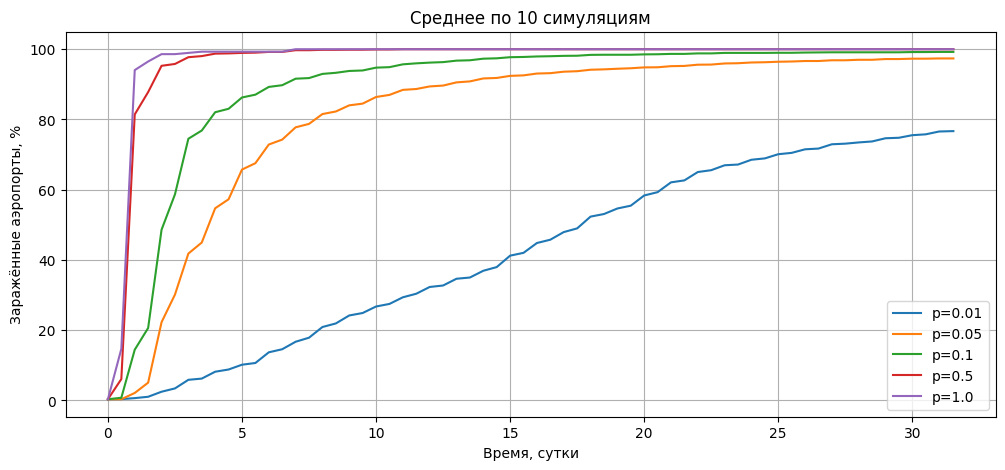

In [5]:
for p in probabilities:
    plt.plot(time_grid / 1440, mean_percent[p], label=f"p={p}")
plt.xlabel("Время, сутки")
plt.ylabel("Заражённые аэропорты, %")
plt.title("Среднее по 10 симуляциям")
plt.legend()
plt.grid()
plt.show()

Чем выше p, тем быстрее распространяется инфекция. Многочисленные рейсы помогают
болезни распространяться даже при малой вероятности передачи. Полное заражение
за месяц зависит и от p, и от расписания.

## Часть 3. Характеристики графа и время заражения

In [6]:
G = nx.Graph()
G.add_nodes_from(nodes)
routes = flights.groupby(["origin", "destination"]).size()
for (a, b), count in routes.items():
    if G.has_edge(a, b):
        G[a][b]["weight"] += count / len(flights)
    else:
        G.add_edge(a, b, weight=count / len(flights))

print("Вершин:", G.number_of_nodes(), "Рёбер:", G.number_of_edges())

Вершин: 286 Рёбер: 2319


Проводим 50 симуляций с p=0.5. Для незаражённых аэропортов оставляем `inf`,
чтобы не занижать медиану. Время измеряем в часах от начала симуляции.

In [7]:
runs_part3 = [simulate_si(0, 0.5) for _ in range(50)]
infection_hours = pd.DataFrame(np.inf, index=range(50), columns=nodes)
for i, run in enumerate(runs_part3):
    for time, airports in run.items():
        for airport in airports:
            infection_hours.loc[i, airport] = time / 60

metrics = pd.DataFrame({
    "median_hours": infection_hours.median(),
    "clustering": pd.Series(nx.clustering(G)),
    "degree": pd.Series(dict(G.degree())),
    "betweenness": pd.Series(nx.betweenness_centrality(G)),
})
metrics.head().round(3)

,median_hours,clustering,degree,betweenness
ABE,0.000,1.000,7,0.000
ABI,17.817,0.000,1,0.000
ABQ,15.317,0.671,37,0.002
ABY,33.950,0.000,1,0.000
ACT,16.142,0.000,1,0.000


In [8]:
analysis = metrics.drop("ABE").replace(np.inf, np.nan).dropna()
correlations = analysis.rank().corr()["median_hours"].drop("median_hours")
print("Аэропортов без конечной медианы:", len(metrics) - 1 - len(analysis))
correlations.round(3)

Аэропортов без конечной медианы: 0


clustering    -0.178
degree        -0.789
betweenness   -0.575
Name: median_hours, dtype: float64

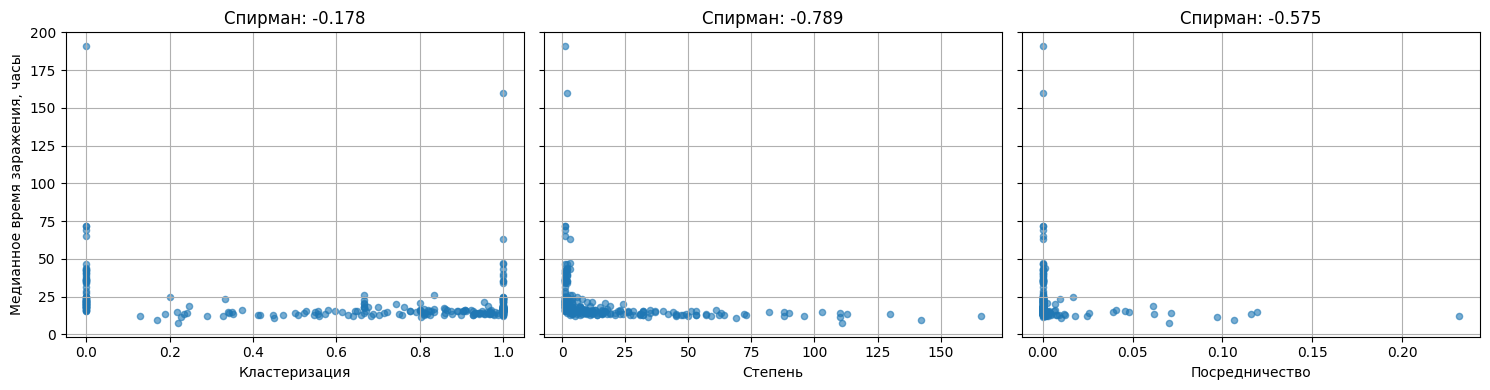

In [9]:
labels = {"clustering": "Кластеризация", "degree": "Степень", "betweenness": "Посредничество"}
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (column, label) in zip(axes, labels.items()):
    ax.scatter(analysis[column], analysis["median_hours"], alpha=0.6, s=20)
    ax.set_xlabel(label)
    ax.set_title(f"Спирман: {correlations[column]:.3f}")
    ax.grid()
axes[0].set_ylabel("Медианное время заражения, часы")
plt.tight_layout()
plt.show()

In [10]:
strongest = correlations.abs().idxmax()
print("Самая сильная связь:", labels[strongest], f"(ρ = {correlations[strongest]:.3f})")

Самая сильная связь: Степень (ρ = -0.789)


## Вывод

Степень сильнее остальных метрик и связана со временем заражения.
Можно сделать вывод, что чем больше у аэропорта соседей, тем больше возможных источников инфекции,
поэтому такие аэропорты обычно заражаются раньше. Отрицательная корреляция это подтверждает.